# Learning Across Generations

*The Mathematics of Machine Intelligence · Chapter 24*

Pass knowledge down a chain of learners, and see what a sample loses and where a chain settles.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask how large each sample is, how rare the detail is, and whether each step sees only the last step's output or can return to the original. Use the missing-answer formula for one step. Use the reader comparison to ask whether the step keeps the likeliest version or samples in proportion to the weights. Report the chance of loss, say that the sample-only copier cannot get the detail back, and name what restores it: links back to the original.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 24, Learning Across Generations: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def miss_probability(p, n):
    """(1 - p)^n: the chance an answer with chance p on each draw never appears in n independent draws."""
    return (1.0 - p) ** n

def draws_for_even_odds(p):
    """Smallest number of draws after which the answer has appeared with chance at least one half."""
    return int(math.ceil(math.log(0.5) / math.log(1.0 - p) - 1e-12))
P_VALUES = [0.005, 0.01, 0.02, 0.05]
N_VALUES = [25, 50, 100, 200, 500]

def loss_picture(p=0.01, n=100):
    miss = miss_probability(p, n)
    fig, ax = panels()
    k = np.arange(0, n + 1)
    ax[0].plot(k, (1 - p) ** k, color=TEAL)
    ax[0].plot([n], [miss], marker='o', color=NAVY, markersize=8, zorder=5)
    ax[0].axhline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[0], n * 0.5, 0.12, f'still missing after {n} draws: {sig(miss)}', fontsize=10)
    ax[0].set(xlabel='draws taken so far', ylabel='chance the answer has not appeared', ylim=(0, 1.05), xlim=(0, n * 1.02), title=f'One answer, chance {p:g} per draw')
    grid = np.arange(0, 501)
    for q, color in zip(P_VALUES, [TERRA, DARK_GOLD, TEAL, NAVY]):
        ax[1].plot(grid, (1 - q) ** grid, color=color, linewidth=2.6 if q == p else 1.2, alpha=1 if q == p else 0.6, label=f'chance {q:g}')
    ring(ax[1], n, miss)
    ax[1].axhline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].legend(fontsize=9, loc='upper right', title='per-draw chance', title_fontsize=9)
    ax[1].set(xlabel='size of the sample passed on', ylabel='chance the answer is missing', ylim=(0, 1.05), xlim=(0, 500), title='Every case, selected one ringed')
    metrics = {'Chance it never appears': sig(miss), 'Chance it appears at least once': sig(1 - miss), 'Expected appearances in the sample': sig(n * p), 'Draws for even odds of seeing it': str(draws_for_even_odds(p))}
    summary = f'An answer with chance {p:g} per draw is missing from all {n} draws {sig(100 * miss)} percent of the time. If the next learner can produce only what its sample contains, a missing answer is gone from that learner.'
    calc = f'P(missing) = (1 - {p:g})^{n} = {sig(1 - p, 6)}^{n} = {sig(miss)}. Even odds of seeing it need {draws_for_even_odds(p)} draws.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def clause_weights(prior, fidelity, false_positive=None):
    """Weights for 'the writer held the clause' (S) and 'did not' (O), given a page that carries the clause."""
    fp = 1.0 - fidelity if false_positive is None else false_positive
    return (prior * fidelity, (1.0 - prior) * fp)

def clause_posterior(prior, fidelity, false_positive=None):
    """Bayes' rule for S given the page with the clause; None when both weights are zero (undefined)."""
    w_s, w_o = clause_weights(prior, fidelity, false_positive)
    if w_s + w_o == 0:
        return None
    return w_s / (w_s + w_o)

def best_guess_verdict(posterior):
    if posterior is None:
        return 'undefined (both weights are zero)'
    if abs(posterior - 0.5) < 1e-09:
        return 'tie (the weights are equal)'
    return 'keeps the clause' if posterior > 0.5 else 'drops the clause'
PRIORS = [0.1, 0.2, 0.3, 0.5]
FIDELITIES = [0.6, 0.7, 0.8, 0.9, 0.95]

def clause_picture(prior=0.2, fidelity=0.7):
    w_s, w_o = clause_weights(prior, fidelity)
    post = clause_posterior(prior, fidelity)
    verdict = best_guess_verdict(post)
    fig, ax = panels()
    ax[0].barh([1, 0], [w_s, w_o], color=[TEAL, GOLD], height=0.55)
    ax[0].set_yticks([1, 0])
    ax[0].set_yticklabels(['writer held\nthe clause (S)', 'writer did not\n(O)'], fontsize=9)
    top = max(w_s, w_o, 0.05)
    for y, v, label in ((1, w_s, f'{prior:g} x {fidelity:g} = {sig(w_s)}'), (0, w_o, f'{sig(1 - prior)} x {sig(1 - fidelity)} = {sig(w_o)}')):
        tag(ax[0], v + top * 0.03, y, label, ha='left', fontsize=9)
    ax[0].set(xlim=(0, top * 1.9), xlabel='weight = prior x chance of the page', title='Weights behind the page with the clause')
    ax[0].text(0.97, 0.5, f'share of weight on S: {sig(post)}\nbest-guess reader:\n{verdict}', transform=ax[0].transAxes, ha='right', va='center', fontsize=9, color=NAVY, bbox={'facecolor': 'white', 'edgecolor': NAVY, 'pad': 4})
    grid = np.linspace(0.5, 0.995, 100)
    fixed_fp = prior * grid / (prior * grid + (1 - prior) * 0.3)
    follow = prior * grid / (prior * grid + (1 - prior) * (1 - grid))
    ax[1].plot(grid, follow, color=TEAL, label='false-positive rate = 1 - fidelity')
    ax[1].plot(grid, fixed_fp, color=TERRA, linestyle='dashed', label='false-positive rate stays 0.3')
    ax[1].axhline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    threshold = 1 - prior
    if 0.5 <= threshold < 0.995:
        ax[1].axvline(threshold, color=GREY, linestyle='dotted', linewidth=1)
        tag(ax[1], threshold, 0.07, f'tie at fidelity {threshold:g}', fontsize=9)
    if post is not None:
        ring(ax[1], fidelity, post)
    ax[1].legend(fontsize=8, loc='upper left')
    ax[1].set(xlabel='copying fidelity', ylabel='belief the writer held the clause', ylim=(0, 1.02), xlim=(0.5, 1.0), title=f'Posterior, prior {prior:g}')
    metrics = {'Weight if held (S)': sig(w_s), 'Weight if not (O)': sig(w_o), 'Share of weight on S (posterior)': 'undefined (both weights are zero)' if post is None else sig(post), 'Best-guess reader': verdict}
    sampling = '' if post is None else f' A sampling reader adopts the clause about {sig(10 * post, 2)} times in 10.'
    summary = f"With prior {prior:g} and fidelity {fidelity:g} the page favors {('S' if w_s > w_o else 'O')} (weights {sig(w_s)} and {sig(w_o)}).{sampling}"
    calc = f"Weight S = {prior:g} x {fidelity:g} = {sig(w_s)}. Weight O = {sig(1 - prior)} x {sig(1 - fidelity)} = {sig(w_o)}. Posterior = {sig(w_s)} / ({sig(w_s)} + {sig(w_o)}) = {(sig(post) if post is not None else 'undefined')}. With false positives 1 - fidelity, a tie falls at fidelity 1 - prior = {sig(1 - prior)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def reader_transition(fidelity, reader, prior=0.2):
    """Chance that the next writer holds the clause, given that this one does (ss) or does not (os).

    The page carries the clause with chance `fidelity` if the writer holds it and `1 - fidelity` if not.
    The next reader adopts the clause with the posterior (sampling) or when the posterior is above one half (best guess)."""
    fp = 1.0 - fidelity
    q_clause = prior * fidelity / (prior * fidelity + (1 - prior) * fp)
    q_blank = prior * (1 - fidelity) / (prior * (1 - fidelity) + (1 - prior) * (1 - fp))

    def adopt(q):
        if reader == 'sampling':
            return q
        if abs(q - 0.5) < 1e-09:
            return 0.5
        return 1.0 if q > 0.5 else 0.0
    a1, a0 = (adopt(q_clause), adopt(q_blank))
    return (fidelity * a1 + (1 - fidelity) * a0, fp * a1 + (1 - fp) * a0)

def chain_trajectory(fidelity, reader, generations=20, prior=0.2):
    stay, enter = reader_transition(fidelity, reader, prior)
    share, path = (1.0, [1.0])
    for _ in range(generations):
        share = share * stay + (1 - share) * enter
        path.append(share)
    return np.array(path)

def long_run_share(fidelity, reader, prior=0.2):
    """Stationary share holding the clause, or None if the chain has no single long-run share."""
    stay, enter = reader_transition(fidelity, reader, prior)
    leave = 1.0 - stay
    if enter + leave < 1e-12:
        return None
    return enter / (enter + leave)

def memory_rate(fidelity, reader, prior=0.2):
    """Second eigenvalue of the two-state chain: how much of the starting difference survives each step."""
    stay, enter = reader_transition(fidelity, reader, prior)
    return stay - enter
CHAIN_FIDELITIES = [0.6, 0.7, 0.75, 0.85, 0.9, 0.95, 0.99]

def chain_picture(fidelity=0.7, reader='sampling'):
    other = 'best guess' if reader == 'sampling' else 'sampling'
    path = chain_trajectory(fidelity, reader)
    path_other = chain_trajectory(fidelity, other)
    lr = long_run_share(fidelity, reader)
    lam = memory_rate(fidelity, reader)
    fig, ax = panels()
    gens = np.arange(len(path))
    ax[0].plot(gens, path, color=TEAL, marker='o', markersize=3.5, label=f'{reader} readers')
    ax[0].plot(gens, path_other, color=TERRA, linestyle='dashed', linewidth=1.6, label=f'{other} readers')
    ax[0].axhline(0.2, color=DARK_GOLD, linestyle='dotted', linewidth=1.2)
    tag(ax[0], 14.5, 0.235, 'prior 0.2', fontsize=9)
    ax[0].legend(fontsize=9, loc='upper right')
    ax[0].set(xlabel='generations down the chain', ylabel='share of chains whose writer holds the clause', ylim=(-0.03, 1.05), xlim=(0, 20), title=f'Chains started on a holder, fidelity {fidelity:g}')
    grid = np.arange(0.55, 0.995, 0.01)
    grid = grid[np.abs(grid - 0.8) > 1e-09]
    for kind, color, style in (('sampling', TEAL, 'solid'), ('best guess', TERRA, 'dashed')):
        values = np.array([memory_rate(f, kind) for f in grid], dtype=float)
        for mask in (grid < 0.8, grid > 0.8):
            ax[1].plot(grid[mask], values[mask], color=color, linestyle=style, label=f'{kind} readers' if mask[0] else None)
    ring(ax[1], fidelity, lam)
    ax[1].axvline(0.8, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.8, 0.5, 'best-guess\nswitch at 0.8', fontsize=9)
    ax[1].legend(fontsize=9, loc='upper left')
    ax[1].set(xlabel='copying fidelity', ylabel='memory kept per generation', ylim=(-0.03, 1.02), xlim=(0.55, 1.0), title='How long a chain remembers its start')
    metrics = {'After 1 generation': sig(path[1]), 'After 10 generations': sig(path[10]), 'Long-run share': 'undefined (no single long-run share)' if lr is None else sig(lr), 'Memory kept per generation': sig(lam)}
    if reader == 'sampling':
        summary = f'At fidelity {fidelity:g} a chain of sampling readers drifts to the prior, 0.2, whatever it started on. The higher the fidelity, the slower it forgets (memory {sig(lam)} per generation).'
    else:
        summary = f"At fidelity {fidelity:g} a chain of best-guess readers {('loses the clause after one step' if fidelity < 0.8 else 'keeps it, settling at one half instead of the prior')}. This is arithmetic on the chapter's two-state example, not a result from the papers."
    calc = f'Next writer holds the clause with chance {sig(reader_transition(fidelity, reader)[0])} if this one does, and {sig(reader_transition(fidelity, reader)[1])} if not. Memory = {sig(reader_transition(fidelity, reader)[0])} - {sig(reader_transition(fidelity, reader)[1])} = {sig(lam)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
P0 = 0.01
CHAINS = 2000
GENERATIONS = 30
COPY_N = [25, 50, 100, 200, 500]
RESTORE = [0.0, 0.05, 0.1, 0.3]

@lru_cache(maxsize=None)
def copier_chains(n, restore, p0=P0, chains=CHAINS, generations=GENERATIONS, seed=2024):
    """Frequency of one rare answer down chains of plain copiers.

    Each generation draws n items; each draw comes from the original source with chance `restore`, otherwise from the
    previous generation. The next copier reproduces exactly what its sample holds (frequency = count / n)."""
    rng = np.random.default_rng([seed, n, int(round(restore * 1000))])
    freq = np.full(chains, p0)
    out = [freq.copy()]
    for _ in range(generations):
        chance = restore * p0 + (1.0 - restore) * freq
        freq = rng.binomial(n, chance) / n
        out.append(freq.copy())
    return np.array(out).T

def absent_share(freq, generation):
    return float(np.mean(freq[:, generation] == 0))

def copier_picture(n=100, restore=0.0):
    freq = copier_chains(n, restore)
    fig, ax = panels()
    gens = np.arange(freq.shape[1])
    for row in freq[:10]:
        ax[0].plot(gens, row, color=TEAL, alpha=0.35, linewidth=1.1)
    ax[0].plot(gens, freq.mean(axis=0), color=NAVY, linewidth=2.4, label=f'mean of {freq.shape[0]} chains')
    ax[0].axhline(P0, color=DARK_GOLD, linestyle='dashed', linewidth=1.2, label='start: 1 in 100')
    ax[0].legend(fontsize=9, loc='upper left')
    ax[0].set(xlabel='generation', ylabel='share of the sample giving the rare answer', ylim=(0, 0.1), xlim=(0, GENERATIONS), title=f'Ten chains and the mean (clipped at 0.1)')
    cells = np.array([[absent_share(copier_chains(m, r), GENERATIONS) for m in COPY_N] for r in RESTORE])
    im = ax[1].imshow(cells, origin='lower', cmap='YlOrBr', vmin=0, vmax=1, aspect='auto')
    for i, r in enumerate(RESTORE):
        for j, m in enumerate(COPY_N):
            ax[1].text(j, i, f'{cells[i, j]:.2f}', ha='center', va='center', fontsize=9, color='white' if cells[i, j] > 0.55 else NAVY)
    ax[1].add_patch(plt.Rectangle((COPY_N.index(n) - 0.5, RESTORE.index(restore) - 0.5), 1, 1, fill=False, edgecolor=NAVY, linewidth=3, zorder=6))
    ax[1].set_xticks(range(len(COPY_N)))
    ax[1].set_xticklabels([str(m) for m in COPY_N])
    ax[1].set_yticks(range(len(RESTORE)))
    ax[1].set_yticklabels([f'{r:g}' for r in RESTORE])
    ax[1].grid(False)
    ax[1].set(xlabel='sample size per generation', ylabel='share drawn from the original', title=f'Chains without it, generation {GENERATIONS}')
    gen1 = absent_share(freq, 1)
    metrics = {'Missing after generation 1 (simulated)': sig(gen1), 'Missing after generation 1 (formula)': sig(miss_probability(P0, n)), f'Missing after generation {GENERATIONS}': sig(absent_share(freq, GENERATIONS)), f'Mean share after generation {GENERATIONS}': sig(freq[:, GENERATIONS].mean())}
    summary = f'With samples of {n} and {restore:g} of each sample taken from the original, the rare answer is missing from {sig(100 * absent_share(freq, GENERATIONS))} percent of {freq.shape[0]} seeded chains by generation {GENERATIONS}. A chain that hits zero stays there unless the original is drawn on.'
    calc = f'Each generation: count ~ Binomial({n}, r p0 + (1 - r) x), x = last share, r = {restore:g}, p0 = 0.01; next share = count / {n}. Generation 1 check: (1 - 0.01)^{n} = {sig(miss_probability(P0, n))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PERPLEXITY = {'start': ('Start (OPT-125m on original data)', 34.0, "given in the paper's text"), 'gen1': ('After 1 generation, no original examples kept', 60.0, "read by eye from the paper's figure"), 'gen9': ('After 9 generations, no original examples kept', 52.0, "read by eye from the paper's figure"), 'gen9_10pct': ('After 9 generations, 10 percent original kept', 37.0, "read by eye from the paper's figure")}
PROMPT_OUTPUTS = [(0, 'Revival architecture and a cathedral in London'), (1, 'basilicas in Rome and Buenos Aires'), (5, 'something translated into more than 100 languages, then a list of them'), (9, 'one word of architecture, then jackrabbits: black-tailed, white-tailed, blue-tailed, red-tailed, and a fifth cut off mid-word')]
ROW_FOR_BAR = {'start': 0, 'gen1': 1, 'gen9': 3, 'gen9_10pct': 3}

def perplexity_picture(bar='gen9'):
    keys = list(PERPLEXITY)
    label, value, how = PERPLEXITY[bar]
    fig, ax = panels([0.9, 1.3])
    colors = [NAVY if k == bar else TEAL for k in keys]
    bars = ax[0].bar(range(4), [PERPLEXITY[k][1] for k in keys], color=colors, width=0.62)
    for k, b in zip(keys, bars):
        if PERPLEXITY[k][2].startswith('read'):
            b.set_hatch('//')
            b.set_edgecolor('white')
        tag(ax[0], b.get_x() + b.get_width() / 2, PERPLEXITY[k][1] + 1.5, ('about ' if PERPLEXITY[k][2].startswith('read') else '') + f'{PERPLEXITY[k][1]:g}', va='bottom', fontsize=10)
    ax[0].set_xticks(range(4))
    ax[0].set_xticklabels(['start', 'gen 1', 'gen 9', 'gen 9,\n10% kept'], fontsize=9)
    ax[0].set(ylabel='perplexity (lower is better)', ylim=(0, 75), title='Reported scores (hatched: read by eye)')
    ax[1].axis('off')
    ax[1].set_title('One printed prompt, four generations', fontsize=12)
    active = ROW_FOR_BAR[bar]
    slot = 0.245
    for i, (gen, text) in enumerate(PROMPT_OUTPUTS):
        top = 0.97 - i * slot
        on = i == active
        ax[1].add_patch(plt.Rectangle((0.0, top - slot + 0.02), 1.0, slot - 0.03, transform=ax[1].transAxes, facecolor='#f3e6c8' if on else '#f4f6f7', edgecolor=NAVY if on else '#d0d6d8', linewidth=1.8 if on else 0.8))
        ax[1].text(0.03, top - 0.02, f'generation {gen}', transform=ax[1].transAxes, fontsize=9, fontweight='bold', va='top', color=NAVY)
        ax[1].text(0.03, top - 0.07, '\n'.join(_wrap(text, 46)), transform=ax[1].transAxes, fontsize=8.5, va='top')
    ratio = value / PERPLEXITY['start'][1]
    metrics = {'Perplexity': f"{('about ' if how.startswith('read') else '')}{value:g}", 'Source of the number': how, "Ratio to the start (companion's arithmetic)": sig(ratio)}
    summary = f"{label}: perplexity {('about ' if how.startswith('read') else '')}{value:g}, {sig(ratio)} times the start. Only the start (34) is printed in the paper's text; the rest are read by eye, and the 10 percent run also trained for ten epochs against five."
    calc = f'Ratio = {value:g} / 34 = {sig(ratio)}. The gap between 52 and 37 mixes the 10 percent of original data with a longer training run, so it does not isolate the 10 percent.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def _wrap(text, width):
    words, lines, line = (text.split(), [], '')
    for word in words:
        if len(line) + len(word) + (1 if line else 0) > width:
            lines.append(line)
            line = word
        else:
            line = (line + ' ' + word).strip()
    if line:
        lines.append(line)
    return lines
TOTAL_CHAINS, RISING_FINAL, FALLING_FINAL, UNSETTLED, RISING_STARTS = (32, 28, 3, 1, 8)

def others_rising(rising_start_rising):
    """Chains that began elsewhere and ended rising: 28 minus those of the 8 rising-start chains that ended rising."""
    return RISING_FINAL - rising_start_rising

def kalish_picture(rising_start=8):
    elsewhere = TOTAL_CHAINS - RISING_STARTS
    up = others_rising(rising_start)
    other_end = elsewhere - up
    fig, ax = panels()
    rows = [(1, rising_start, RISING_STARTS - rising_start, f'began rising ({RISING_STARTS})'), (0, up, other_end, f'began elsewhere ({elsewhere})')]
    for y, a, b, name in rows:
        ax[0].barh(y, a, color=TEAL, height=0.55)
        ax[0].barh(y, b, left=a, color=GREY, height=0.55, alpha=0.6)
        if a:
            ax[0].text(a / 2, y, f'{a}', ha='center', va='center', color='white', fontsize=11)
        if b:
            ax[0].text(a + b / 2, y, f'{b}', ha='center', va='center', color='white', fontsize=9)
    ax[0].set_yticks([1, 0])
    ax[0].set_yticklabels([r[3] for r in rows], fontsize=9)
    ax[0].set(xlim=(0, 26), xlabel='chains (teal: ended rising, gray: did not)', title=f'Where the {TOTAL_CHAINS} chains ended')
    xs = list(range(4, 9))
    ax[1].bar(xs, [others_rising(x) for x in xs], color=[NAVY if x == rising_start else TEAL for x in xs], width=0.6)
    for x in xs:
        tag(ax[1], x, others_rising(x) + 0.4, str(others_rising(x)), va='bottom', fontsize=9)
    ax[1].axhline(20, color=TERRA, linestyle='dashed', linewidth=1.3)
    tag(ax[1], 5.0, 17.3, 'never below 20', fontsize=9, color=TERRA)
    ax[1].set(xlabel='rising starts that ended rising', ylabel=f'of {elsewhere} other starts, ended rising', ylim=(0, 28), title='What the totals allow', xticks=xs)
    metrics = {'Ended rising': f'{RISING_FINAL} of {TOTAL_CHAINS}', 'Rising-start chains ending rising (assumed)': f'{rising_start} of {RISING_STARTS}', 'Began elsewhere, ended rising': f'{up} of {elsewhere}', 'Other endings': f'{FALLING_FINAL} falling, {UNSETTLED} unsettled'}
    summary = f'Twenty-eight of 32 chains ended on a rising line, but eight began on one. If {rising_start} of those eight ended rising, then {up} of the {elsewhere} that began elsewhere did. Whatever the split, at least 20 did.'
    calc = f'Began elsewhere and ended rising = 28 - {rising_start} = {up}. The smallest it can be is 28 - 8 = 20, so at least 20 of 24.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C24-D01: How likely is a rare answer to vanish in one handoff?

A rare answer has a 1 in 100 chance on each draw, and the next learner trains on 100 draws. How likely is the answer to be missing from the sample?

Each draw misses the answer with the leftover chance 1 - p. Missing it every time multiplies that leftover chance by itself, once per draw. With more draws the product falls, but slowly when p is small, so rare answers need large samples to survive.

$$
P(\text{missing})=(1-p)^{n}
$$

**Symbols:** p: chance of the rare answer on one draw, between zero and one; n: number of draws in the sample passed on; 1 - p: chance of missing the answer on one draw

**Predict before looking:** Before moving the sliders, predict how many draws are needed before a 1 in 100 answer has even odds of having appeared at all.

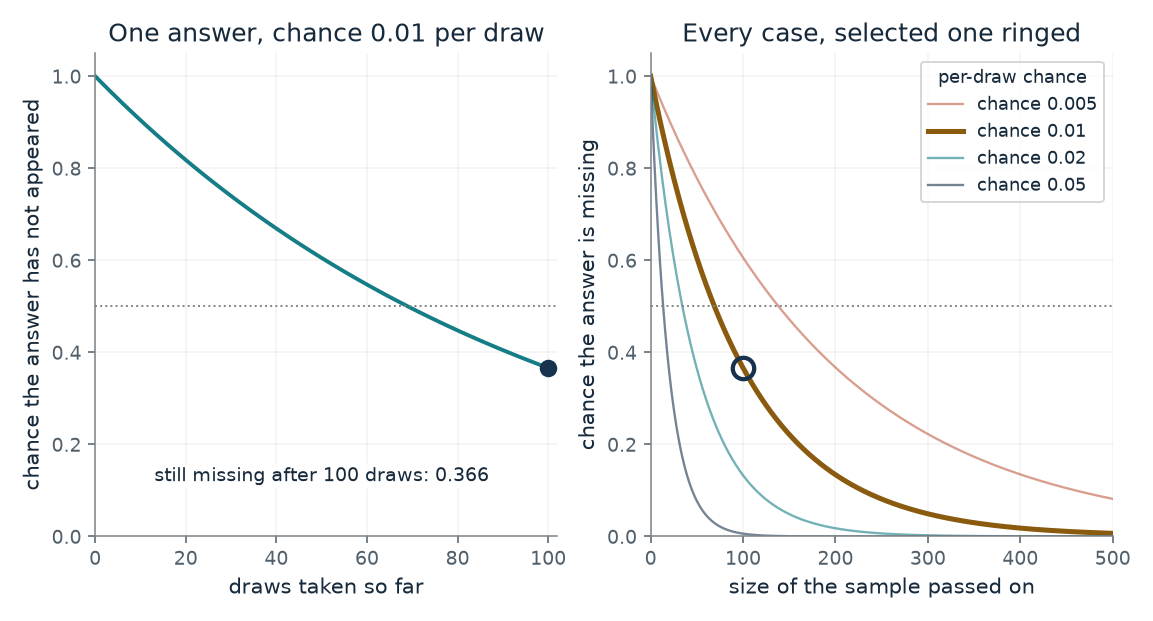

- **Chance it never appears:** 0.366
- **Chance it appears at least once:** 0.634
- **Expected appearances in the sample:** 1
- **Draws for even odds of seeing it:** 69

An answer with chance 0.01 per draw is missing from all 100 draws 36.6 percent of the time. If the next learner can produce only what its sample contains, a missing answer is gone from that learner.

P(missing) = (1 - 0.01)^100 = 0.99^100 = 0.366. Even odds of seeing it need 69 draws.

In [2]:
figure, values, explanation = loss_picture(**{'p': 0.01, 'n': 100})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How likely is a rare answer to vanish in one handoff?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance of the rare answer on one draw = 0.01, Draws in the sample = 100: A 1 in 100 answer is missing from a 100-item sample 37 percent of the time. It takes 69 draws just to reach even odds of seeing it once, which is why a sample the size of the reciprocal of p is not enough.

**Takeaway:** A sample the same size as 1 divided by p misses the answer about 37 percent of the time, and only a much larger sample makes the loss unlikely.

**Why it matters:** Whenever a copy is made from a sample of a copy, rare details are the first to go, and the formula says how fast. Where outside material is not brought back, the loss is permanent for a plain copier.

**In brains and behavior:** Bartlett's readers rebuilt a tale rather than copying it, so this formula is not an account of what they did.

**In machines:** For a model retrained on its own samples, the formula is the chapter's illustration of why rare content can go first. The paper did not count rare answers in OPT-125m.

**Where it applies:** Draws are independent. The next learner is a plain copier that can produce only answers present in its sample; a more general model might keep earlier knowledge or generalize to an unseen answer.

**Check your understanding:** With p = 0.02 and a sample of 50, how likely is the answer to be missing, and is the sample comfortably safe?

<details><summary>Show the answer</summary>

(0.98)^50 is about 0.364. A 2 in 100 answer is missing from a 50-item sample more than a third of the time, so the sample is not safe.

</details>

*Source: Chapter 24, A small model fed its own text ended up writing about jackrabbits. Book formula and constructed example (the chapter's 1 in 100 answer and 100 samples, recomputed exactly). The other values of p and n are this companion's variations. No simulation or data is used here.*

## C24-D02: Why does a page carrying the clause favor no clause?

A reader sees a page with the odd clause. Before reading, the clause was 0.2 likely to be held. Writers copy a held clause 7 times in 10 and add an absent one 3 times in 10. What does the reader believe?

Each story gets a weight: its prior times the chance it produces this page. The share of the total on the clause is the posterior. A best-guess reader adopts whichever story weighs more. A sampling reader adopts the clause with a chance equal to its share of the total weight.

$$
P(S\mid d)=\frac{P(S)P(d\mid S)}{P(S)P(d\mid S)+P(O)P(d\mid O)}
$$

**Symbols:** S, O: the writer held the clause (S) or did not (O); d: the observed page, which carries the clause; P(S): the prior, the belief before reading; P(d | S): copying fidelity: the chance a holder puts the clause on the page; P(d | O): the false-positive rate: the chance a non-holder adds it (here 1 minus fidelity)

**Predict before looking:** Predict whether a reader who sees the clause on the page should believe the writer held it. Then predict how much higher the fidelity must be for a best-guess reader to keep it.

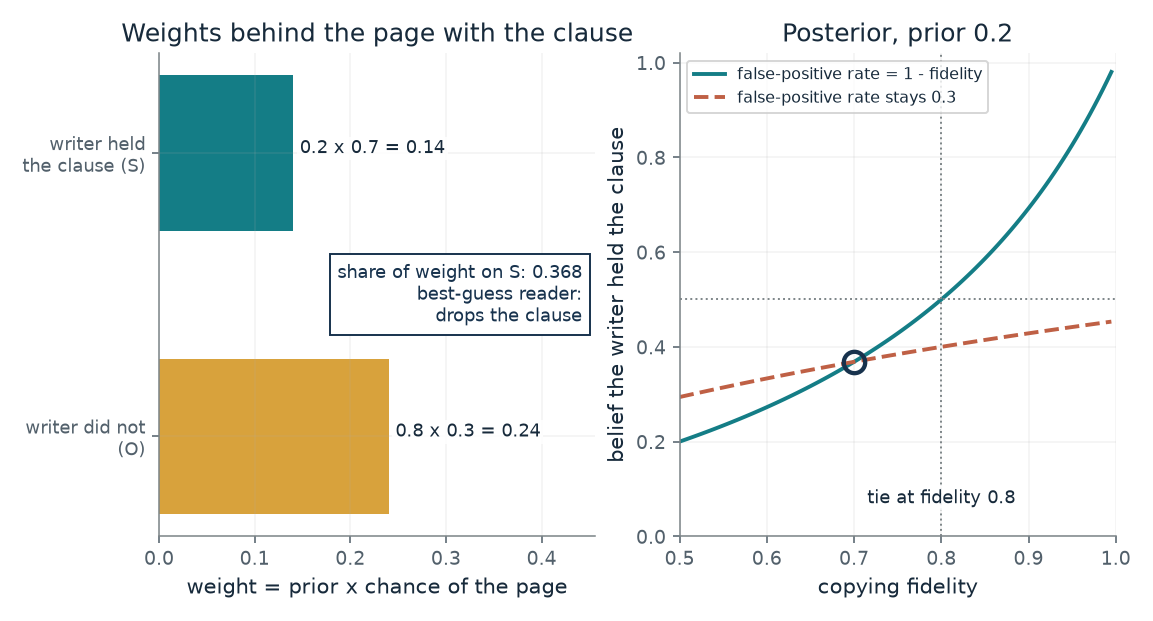

- **Weight if held (S):** 0.14
- **Weight if not (O):** 0.24
- **Share of weight on S (posterior):** 0.368
- **Best-guess reader:** drops the clause

With prior 0.2 and fidelity 0.7 the page favors O (weights 0.14 and 0.24). A sampling reader adopts the clause about 3.7 times in 10.

Weight S = 0.2 x 0.7 = 0.14. Weight O = 0.8 x 0.3 = 0.24. Posterior = 0.14 / (0.14 + 0.24) = 0.368. With false positives 1 - fidelity, a tie falls at fidelity 1 - prior = 0.8.

In [3]:
figure, values, explanation = clause_picture(**{'prior': 0.2, 'fidelity': 0.7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a page carrying the clause favor no clause?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Prior that the writer held the clause = 0.2, Copying fidelity = 0.7: The weights are 0.14 for held and 0.24 for not held, so the page favors no clause even though it carries the clause. The share on the clause is 0.14 out of 0.38, about 0.37: a best-guess reader drops it, a sampling reader adopts it about 4 times in 10. With a prior of 0.2 the tie falls at fidelity 0.8.

**Takeaway:** A best-guess reader needs the page to be convincing enough to overcome a low prior, and a false-positive rate that does not shrink with fidelity can make that impossible.

**Why it matters:** A minority detail that is common enough to keep turning up on pages can still be dropped every time by a reader who always takes the likeliest version. That is how a chain can erase a detail that keeps arriving.

**In brains and behavior:** The chapter gives no measurement of how people weigh a clause. Bartlett's account was convention, not arithmetic, and nothing here was fitted to his readers.

**In machines:** Beam search resembles a best-guess reader in preferring likely output. The collapse study used beam search to write each generation's data, so decoding and refitting are tangled and the study cannot say which did the damage.

**Where it applies:** Two explanations, S and O, that cover the possibilities. The false-positive rate equals one minus the fidelity unless the dashed curve is read, where it stays at 0.3. The reader weighs the two stories and cannot ask the writer.

**Check your understanding:** With prior 0.3 and fidelity 0.7 (false positives 0.3), what is the posterior, and what does a best-guess reader do?

<details><summary>Show the answer</summary>

The weights are 0.3 x 0.7 = 0.21 and 0.7 x 0.3 = 0.21, a tie with posterior 0.5. The best-guess rule has no preference, so the reader is at its tipping point.

</details>

*Source: Chapter 24, One odd clause, and two kinds of reader. Book formula and constructed example. The numbers (prior 0.2, fidelity 0.7, false positives 0.3) are the chapter's own arithmetic, chosen for the arithmetic and fitted to nobody. The other priors and fidelities are this companion's variations.*

## C24-D03: Where does a chain of readers end up?

If every writer sees a page from the writer before and rebuilds a belief, does the clause persist down the chain, and does it matter whether readers take the likeliest version or sample?

Each generation has a chance of staying on the clause if the writer held it and a chance of adding it if not. The difference between those two chances is the memory kept per generation. When it is near 1, the chain barely moves. When it is near 0, the chain forgets in a step.

$$
P(S_{t+1}\mid S_t)\;=\;\sum_{d}P(d\mid S_t)\,\mathrm{reader}(d),\qquad \lambda_2=P(S\to S)-P(O\to S)
$$

**Symbols:** S_t: whether the writer at step t holds the clause; reader(d): chance the next writer adopts the clause after page d: the posterior (sampling) or 1 or 0 (best guess); lambda_2: the second eigenvalue: how much of the starting difference survives each generation; prior: 0.2, the shared prior of every learner

**Predict before looking:** Predict what the sampling chain settles on, and whether raising the fidelity toward 1 makes it settle faster or slower.

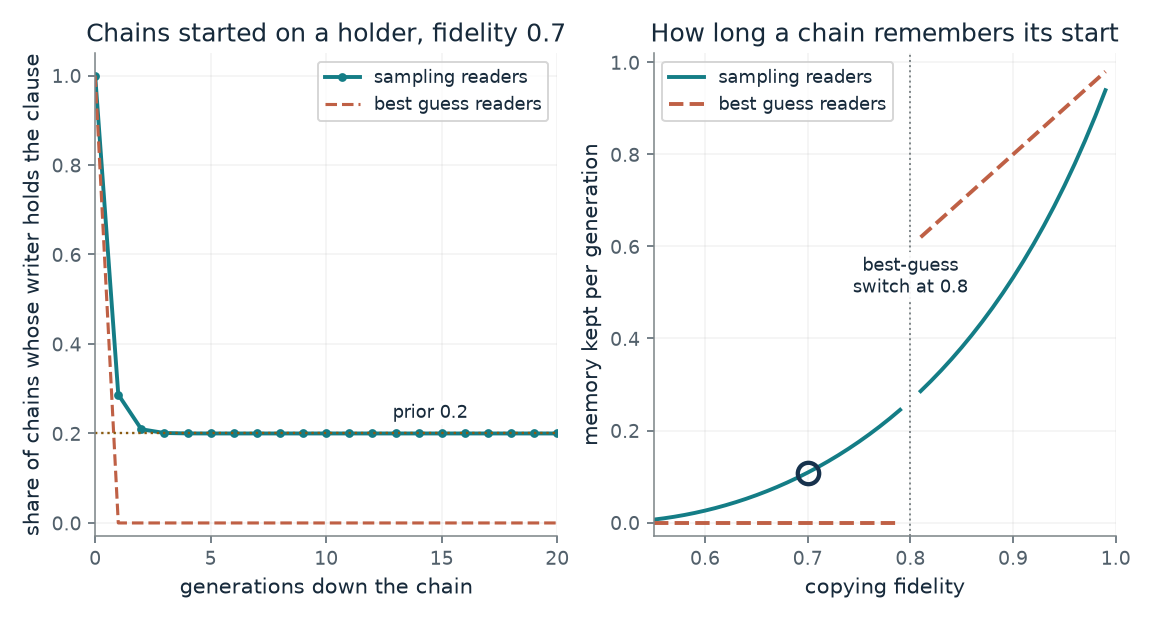

- **After 1 generation:** 0.287
- **After 10 generations:** 0.2
- **Long-run share:** 0.2
- **Memory kept per generation:** 0.109

At fidelity 0.7 a chain of sampling readers drifts to the prior, 0.2, whatever it started on. The higher the fidelity, the slower it forgets (memory 0.109 per generation).

Next writer holds the clause with chance 0.287 if this one does, and 0.178 if not. Memory = 0.287 - 0.178 = 0.109.

In [4]:
figure, values, explanation = chain_picture(**{'fidelity': 0.7, 'reader': 'sampling'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Where does a chain of readers end up?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Copying fidelity = 0.99, Kind of reader = sampling: At fidelity 0.99 a sampling chain still holds the clause in about 63 percent of chains after 10 generations, and it takes more than 30 generations to get near the prior, 0.2. Near-exact copying remembers its start for a long time. At fidelity 1 it would never forget.

**Takeaway:** A chain of sampling readers forgets its start and settles at the prior, and the closer the copy, the longer that takes. A chain of best-guess readers can erase the clause or flatten the share to one half.

**Why it matters:** Near-exact copying preserves an early mistake as well as an early insight, and a likeliest-version rule can wipe out a minority view. A real pipeline that rewrites and samples ends where its steps together send it.

**In brains and behavior:** The student chains were consistent with a pull toward a rising line. Nothing shows the students sampled their beliefs, and the task was bars and sliders, not a story.

**In machines:** The settling result is exact only for idealized learners like these. Nothing shows that near-exact distillation keeps a teacher's first mistakes.

**Where it applies:** Two hypotheses, every learner with the same prior and a correct guess about how pages are made, one page per step, and an exactly computed chain with no sampling noise. The best-guess tie rule is a coin flip. Exact settling at the prior holds only under these conditions; a real pipeline that reads, rewrites and samples ends where all three steps together send it.

**Check your understanding:** At fidelity 0.7, how many generations does a best-guess chain keep the clause, and where does a sampling chain end?

<details><summary>Show the answer</summary>

A best-guess chain drops the clause after one generation, because a page with the clause gives a posterior of 0.37 and a page without gives about 0.10. A sampling chain forgets quickly (memory 0.11 per generation) and sits at the prior, 0.2.

</details>

*Source: Chapter 24, Nine students, a slider, and where a chain ends up. Model built on the chapter's two-state ghost-clause example (prior 0.2, false positives equal to one minus fidelity). The settling of sampling chains at the prior is Griffiths and Kalish's result, stated in the chapter under conditions. The best-guess figures are this companion's arithmetic on the chapter's example, not a result from either paper.*

## C24-D04: Does a chain of copiers lose a rare answer, and can the original bring it back?

A rare answer starts at 1 in 100. Each copier trains on a sample of the one before. How many chains lose it entirely, and what changes if part of each sample comes from the original?

Each generation draws n items, each from the original source with chance r and otherwise from the last generation. The count that gives the rare answer becomes the next generation's share. If the count is zero and r is zero, the answer cannot come back.

$$
x_{t+1}=\frac{K_t}{n},\qquad K_t\sim\mathrm{Binomial}\bigl(n,\;r\,p_0+(1-r)\,x_t\bigr)
$$

**Symbols:** x_t: share of generation t's output that gives the rare answer; n: sample size passed on; r: share of each sample drawn from the original source; p_0: the original share, 0.01

**Predict before looking:** Predict whether the average share after 30 generations stays near 1 in 100 even though many chains reach zero.

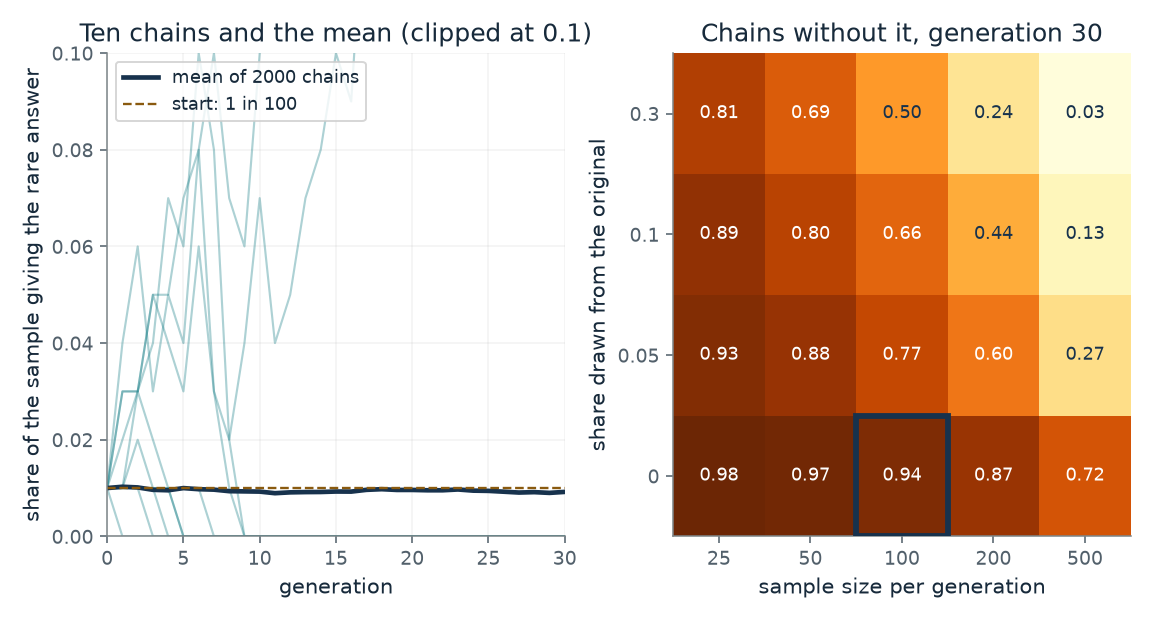

- **Missing after generation 1 (simulated):** 0.364
- **Missing after generation 1 (formula):** 0.366
- **Missing after generation 30:** 0.938
- **Mean share after generation 30:** 0.00921

With samples of 100 and 0 of each sample taken from the original, the rare answer is missing from 93.8 percent of 2000 seeded chains by generation 30. A chain that hits zero stays there unless the original is drawn on.

Each generation: count ~ Binomial(100, r p0 + (1 - r) x), x = last share, r = 0, p0 = 0.01; next share = count / 100. Generation 1 check: (1 - 0.01)^100 = 0.366.

In [5]:
figure, values, explanation = copier_picture(**{'n': 100, 'restore': 0.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Does a chain of copiers lose a rare answer, and can the original bring it back?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sample size per generation = 100, Share of each sample from the original = 0.0: With samples of 100 and no original data, the answer is missing in about 36 percent of chains after one generation, close to the formula's 0.366, and in about 94 percent by generation 30. A chain that reaches zero stays at zero, while the few that drift up keep the mean near 1 in 100.

**Takeaway:** Without a route back to the original, loss is one-way for a plain copier. Drawing even part of each sample from the original keeps the rare answer alive in far more chains.

**Why it matters:** This is the chapter's practical lesson: a link back to the original lets a reader recover what a copy of a copy has lost. The simulation shows the direction and the size of the effect in a constructed case, nothing more.

**In machines:** Gerstgrasser and colleagues found that piling synthetic data on top of real data avoided collapse in the settings they tested. The simulation here does not reproduce that study.

**Where it applies:** A plain copier that reproduces exactly its sample. Draws are independent. The share r stands in for keeping some original data; the paper's 10 percent run also trained for ten epochs against five, so it does not isolate the 10 percent.

**Check your understanding:** In the settings with no original data, which sample size has the smallest share of chains without the answer at generation 30, and why does the mean not shrink with it?

<details><summary>Show the answer</summary>

The largest sample, 500: about 72 percent of chains are still without it at generation 30, against 94 percent at 100, so bigger samples slow the loss without stopping it. The mean stays near 0.01 because at zero original share the expected next share equals the current one: chains that fall to zero are balanced by chains that climb.

</details>

*Source: Chapter 24, What keeps a story alive, and what keeps a model whole. Seeded simulation built from the chapter's 1 in 100 example: 400 chains of 30 generations per setting, seed 2024. It is this companion's construction, not the model-collapse study (which used OPT-125m and did not count rare answers) and not a measurement. The chapter reports only the one-step miss chance and that a run with some original data degraded less.*

## C24-D05: What did a model do to its own text, and how bad was the score?

A small model was retrained again and again on text written by the one before. How did its score on real text change, and what changed when some original data was kept?

Perplexity measures how surprised the model is by real text. It started at 34. With no original target examples in fine-tuning, it jumped at generation 1 and settled near 52 by generation 9. With a random 10 percent of the original kept, it ended near 37.

$$
\text{ratio}=\frac{\text{perplexity}}{34}
$$

**Symbols:** perplexity: how surprised the model is by each next token of real text; lower is better when the test and tokenization are fixed; 34: the starting perplexity, given in the paper's text

**Predict before looking:** Predict whether the score after nine generations is worse than after one, and how close keeping 10 percent of the original gets to the start.

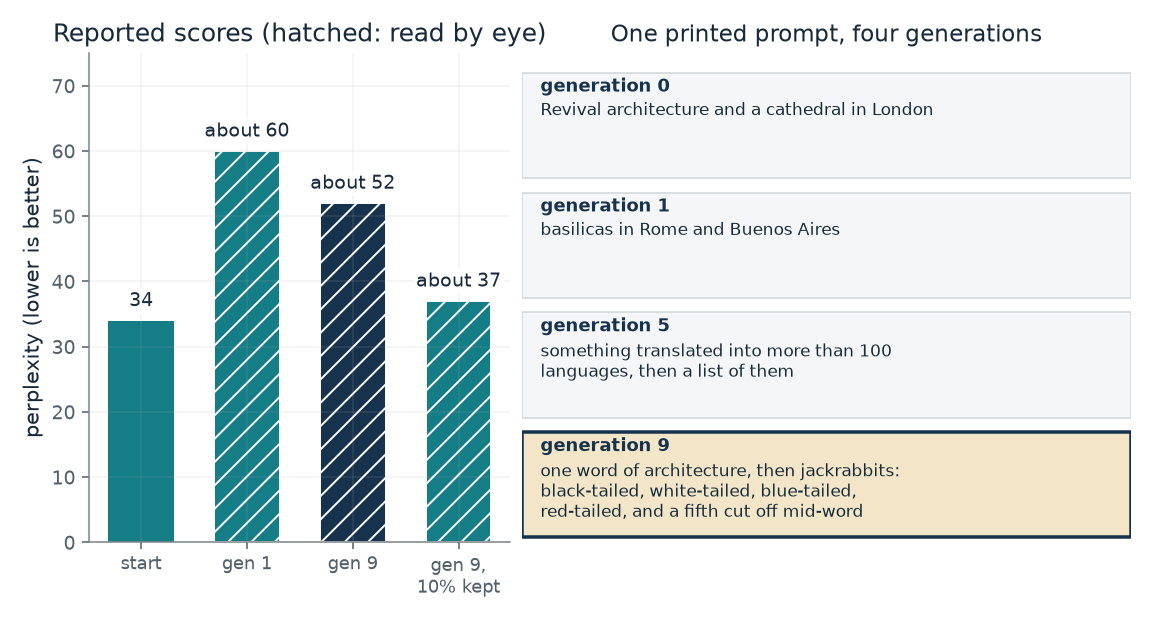

- **Perplexity:** about 52
- **Source of the number:** read by eye from the paper's figure
- **Ratio to the start (companion's arithmetic):** 1.53

After 9 generations, no original examples kept: perplexity about 52, 1.53 times the start. Only the start (34) is printed in the paper's text; the rest are read by eye, and the 10 percent run also trained for ten epochs against five.

Ratio = 52 / 34 = 1.53. The gap between 52 and 37 mixes the 10 percent of original data with a longer training run, so it does not isolate the 10 percent.

In [6]:
figure, values, explanation = perplexity_picture(**{'bar': 'gen9'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What did a model do to its own text, and how bad was the score?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which score = gen9_10pct: With 10 percent of the original data kept, the score ends near 37, against about 52 without it and 34 at the start. The authors report only minor degradation for this run, but it also trained for ten epochs, so the 10 percent alone is not isolated.

**Takeaway:** Retraining on a model's own text raised perplexity from 34 to roughly 60 after one generation and about 52 after nine. Keeping some original data ended near 37.

**Why it matters:** This is the machine chain in the chapter. The printed prompt shows the drift in one case, church towers to jackrabbits, which the chapter says is a sample of the drift and not a rate.

**In machines:** A model trained on a teacher's text can lose rare content and drift toward typical output, which the authors call model collapse. The scores are the evidence here, plus theory.

**Where it applies:** One small model (OPT-125m), generations 0 to 9 only. The 10 percent run also trained for ten epochs against five. Each generation's data was written with beam search, so decoding and refitting are tangled and the study cannot say which did the damage. The paper did not count rare answers in this model.

**Check your understanding:** Why can the chapter not say the 10 percent of original data caused the lower score?

<details><summary>Show the answer</summary>

The 10 percent run also trained for ten epochs against five, so two things changed at once. The study also tangles decoding with refitting, so it cannot say which did the damage.

</details>

*Source: Chapter 24, What keeps a story alive, and what keeps a model whole. Reported values quoted in the chapter from Shumailov and colleagues (Nature, 2024). Only the starting value 34 is printed in the paper's text. The 60, 52 and 37 are read by eye from the paper's figure and are shown as approximate. The ratio is this companion's own arithmetic. The prompt outputs are the paper's one printed example. No simulation is used here.*

## C24-D06: How many of the 32 chains really moved toward a rising line?

28 of 32 chains of students ended on a rising line. Eight chains began on one. How strong is the evidence of a pull toward it?

There were four starting data sets with eight chains each. 28 chains ended on a rising line. Because at most eight of those began there, at least 20 came from the other 24. The unknown is how many of the eight stayed.

$$
\#\{\text{began elsewhere, ended rising}\}=28-x,\qquad 4\le x\le 8
$$

**Symbols:** x: how many of the eight rising-start chains ended rising (not reported, so it is a control); 28: chains that ended on a rising line, out of 32; 24: chains that began on a falling line, a U shape or random pairs

**Predict before looking:** Predict the smallest number of chains that began elsewhere and still ended on a rising line.

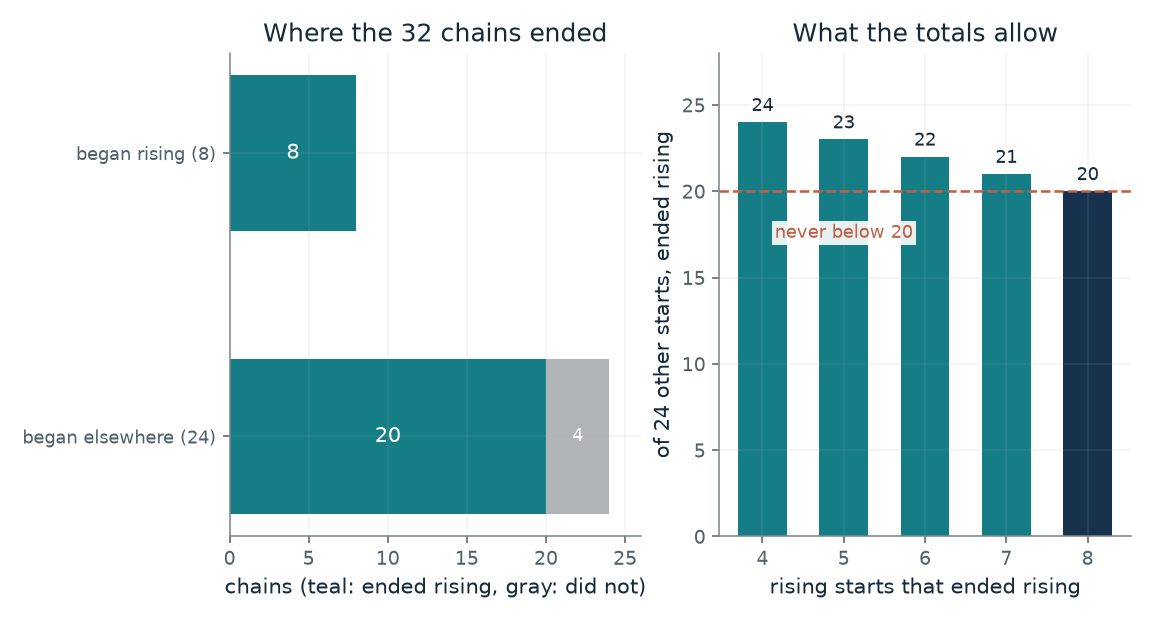

- **Ended rising:** 28 of 32
- **Rising-start chains ending rising (assumed):** 8 of 8
- **Began elsewhere, ended rising:** 20 of 24
- **Other endings:** 3 falling, 1 unsettled

Twenty-eight of 32 chains ended on a rising line, but eight began on one. If 8 of those eight ended rising, then 20 of the 24 that began elsewhere did. Whatever the split, at least 20 did.

Began elsewhere and ended rising = 28 - 8 = 20. The smallest it can be is 28 - 8 = 20, so at least 20 of 24.

In [7]:
figure, values, explanation = kalish_picture(**{'rising_start': 8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many of the 32 chains really moved toward a rising line?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Rising-start chains that ended rising (unreported) = 8: If all eight rising-start chains ended rising, 20 of the 24 chains that began elsewhere did as well, which is the smallest it can be. If some rising-start chains moved away, more of the others ended rising. Either way the pull toward a rising line is real in the counts, though the study did not fit a model.

**Takeaway:** At least 20 of the 24 chains that began elsewhere ended on a rising line, which is what makes the count more than a restatement of the starting data.

**Why it matters:** A headline count can hide how much of it was already there at the start. Subtracting the chains that began on the answer shows what is left, and the chapter does exactly that.

**In brains and behavior:** A behavioral result in 288 undergraduates at one university. It says what chains of learners did on one task, not how any mind works.

**In machines:** The theory of sampling learners predicts settling at the prior. The students were not shown to sample.

**Where it applies:** The experimenters read the pull as consistent with students expecting a rising line. They did not fit a model, and they write that significantly more data would be required to confirm the stable distribution predicted by the theory. The task was bars and sliders, not a story.

**Check your understanding:** If only 5 of the 8 rising-start chains ended rising, how many of the 24 other chains did?

<details><summary>Show the answer</summary>

28 - 5 = 23 of 24, above the floor of 20. Three rising-start chains would then have ended elsewhere, and 1 of the 24 others would not have ended rising: 3 + 1 = the 4 chains that did not end rising.

</details>

*Source: Chapter 24, Nine students, a slider, and where a chain ends up. Reported counts quoted in the chapter from Kalish, Griffiths and Lewandowsky (2007): 288 undergraduates, 32 chains of nine students, eight chains from each of four starting data sets, 28 of 32 ended rising, 3 ended falling, 1 never settled. The count of how many rising-start chains ended rising is not in the chapter, so it is the control. The bound is arithmetic. No simulation is used.*

## Bring it to your own question

Ask how large each sample is, how rare the detail is, and whether each step sees only the last step's output or can return to the original. Use the missing-answer formula for one step. Use the reader comparison to ask whether the step keeps the likeliest version or samples in proportion to the weights. Report the chance of loss, say that the sample-only copier cannot get the detail back, and name what restores it: links back to the original.

Use the `mmi-ch24-learning-across-generations` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.